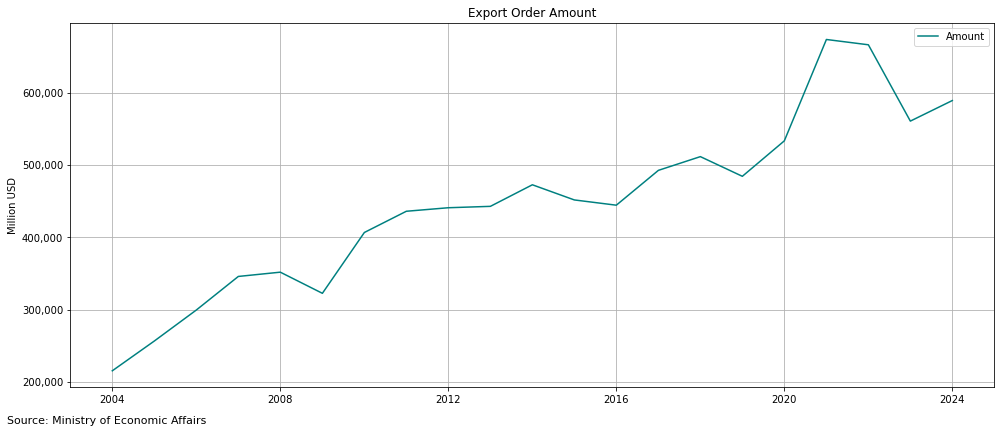

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


file_path = "外銷訂單金額及年增率 (2).xlsx"
df = pd.read_excel(file_path, usecols="A:C", skiprows=2, nrows=22)  

df.columns = ["Year", "Amount", "YGR"]
df["Date"] = pd.to_datetime(df["Year"], format="%Y")
df.set_index("Date", inplace=True)

fmt_amount = FuncFormatter(lambda x, _: f"{x:,.0f}")
fmt_yoy = FuncFormatter(lambda x, _: f"{x:.0f}%")

fig1, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(df.index, df["Amount"], color="teal", label="Amount")
ax1.set_title("Export Order Amount")
ax1.set_ylabel("Million USD")
ax1.grid(True)
ax1.yaxis.set_major_formatter(fmt_amount)
ax1.legend()
plt.tight_layout()

plt.figtext(0.01, 0.01, "Source: Ministry of Economic Affairs", ha='left', fontsize=11)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

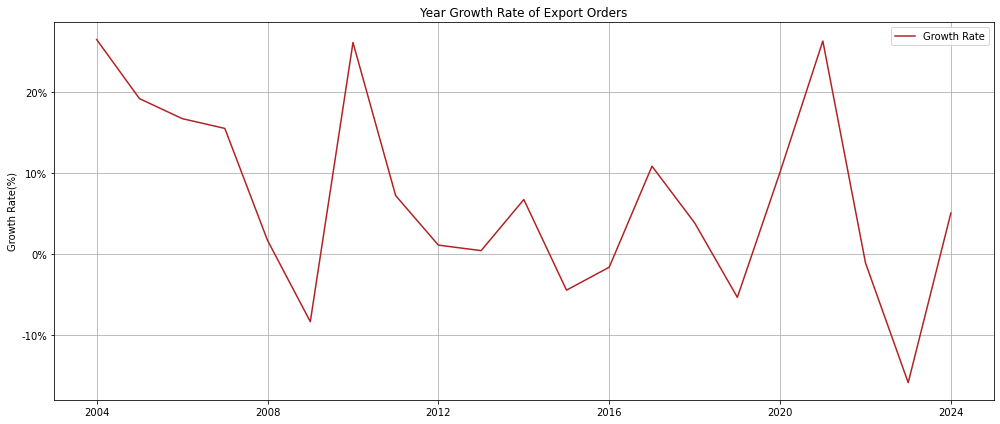

In [4]:
fig3, ax3 = plt.subplots(figsize=(14, 6))
ax3.plot(df.index, df["YGR"], color="firebrick", label="Growth Rate")
ax3.set_title("Year Growth Rate of Export Orders")
ax3.set_ylabel("Growth Rate(%)")
ax3.grid(True)
ax3.yaxis.set_major_formatter(fmt_yoy)
ax3.legend()
plt.tight_layout()

plt.show()

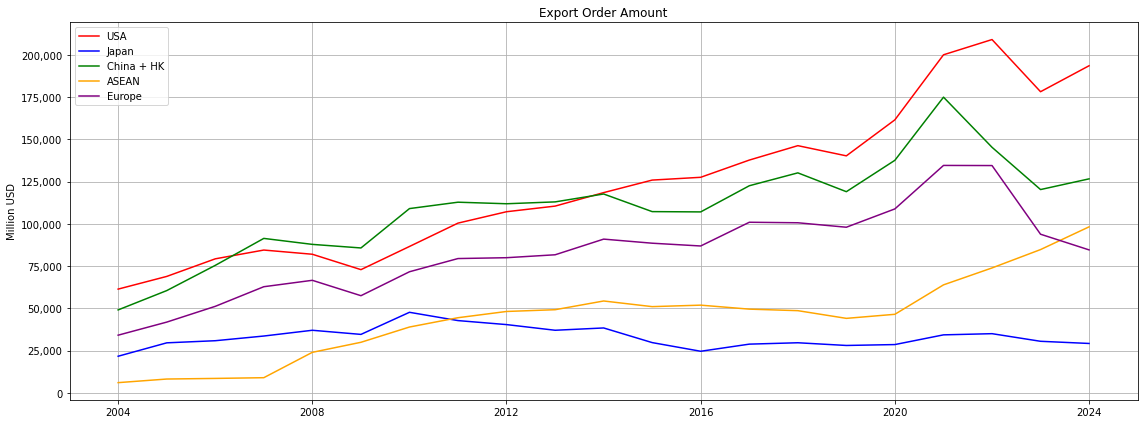

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

file_path = "多國外銷訂單金額及年增率.xls"

USA = pd.read_excel(file_path, usecols="A:C", skiprows=2, nrows=22, engine="xlrd")
Japan = pd.read_excel(file_path, usecols=[4, 5, 6], skiprows=2, nrows=22, engine="xlrd")
China = pd.read_excel(file_path, usecols=[8, 9, 10], skiprows=2, nrows=22, engine="xlrd")
ASEAN = pd.read_excel(file_path, usecols=[12, 13, 14], skiprows=2, nrows=22, engine="xlrd")
Europe = pd.read_excel(file_path, usecols=[16, 17, 18], skiprows=2, nrows=22, engine="xlrd")

df = pd.DataFrame()
df["Year"] = USA.iloc[:, 0]
df["USA_Amount"] = USA.iloc[:, 1]
df["USA_YGR"] = USA.iloc[:, 2]
df["Japan_Amount"] = Japan.iloc[:, 1]
df["Japan_YGR"] = Japan.iloc[:, 2]
df["China_HK_Amount"] = China.iloc[:, 1]
df["China_HK_YGR"] = China.iloc[:, 2]
df["ASEAN_Amount"] = ASEAN.iloc[:, 1]
df["ASEAN_YGR"] = ASEAN.iloc[:, 2]
df["Europe_Amount"] = Europe.iloc[:, 1]
df["Europe_YGR"] = Europe.iloc[:, 2]

df["Date"] = pd.to_datetime(df["Year"], format="%Y")
df.set_index("Date", inplace=True)

regions = { "USA": "USA", "Japan": "Japan", "China_HK": "China + HK","ASEAN": "ASEAN", "Europe": "Europe"}
colors = {"USA": "red", "Japan": "blue", "China_HK": "green", "ASEAN": "orange", "Europe": "purple"}
fmt_amount = FuncFormatter(lambda x, _: f"{x:,.0f}")
fmt_yoy = FuncFormatter(lambda x, _: f"{x:.0f}%")

fig1, ax1 = plt.subplots(figsize=(16, 6))
for r in regions:
    ax1.plot(df.index, df[f"{r}_Amount"], label=regions[r], color=colors[r])
ax1.set_title("Export Order Amount")
ax1.set_ylabel("Million USD")
ax1.legend(); ax1.grid(True)
ax1.yaxis.set_major_formatter(fmt_amount)
plt.tight_layout()
plt.show()

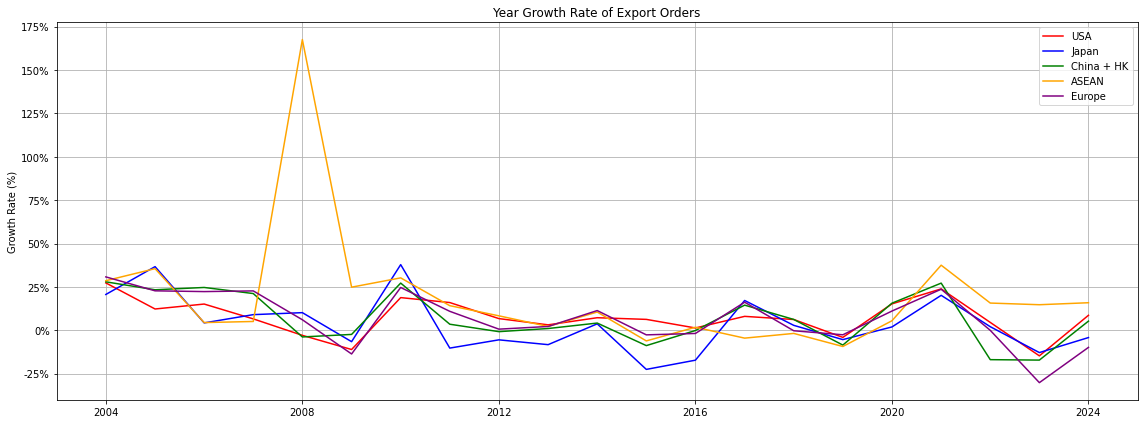

In [8]:
fmt_ygr = FuncFormatter(lambda x, _: f"{x:.0f}%")
fig3, ax3 = plt.subplots(figsize=(16, 6))
for r in regions:
    ax3.plot(df.index, df[f"{r}_YGR"], label=regions[r], color=colors[r])
ax3.set_title("Year Growth Rate of Export Orders")
ax3.set_ylabel("Growth Rate (%)")
ax3.legend(); ax3.grid(True)
ax3.yaxis.set_major_formatter(fmt_ygr)
plt.tight_layout()
plt.show()